# 06 · Polls against results

Part 2 of the study plan (`docs/study_plan.md`): how much coordination the polls show, toward whom, and how they
compare with the result. Built block by block: **structure metrics**, then the split of the change in concentration,
poll error by role, the cliff, the last weeks, momentum, and a table of stylized facts.

Each poll is read through its ballot scenario, with every candidate it tests, including those who will not be on the
ballot: that is what voters saw. Shares are rescaled to 100 unless marked *raw*.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from polls import average, figures, metrics, timeline

pd.set_option("display.width", 200)
TABLES, FIGURES = ROOT / "results" / "tables", ROOT / "results" / "figures"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

calendar = timeline.load(ROOT / "config" / "elections.yaml")
rows = timeline.add_time(pd.read_csv(ROOT / "data" / "final" / "polls.csv", low_memory=False), calendar)
results = pd.read_csv(ROOT / "data" / "interim" / "results.csv")
ELECTIONS = sorted(rows["election"].unique())
ballot = rows[rows["ballot_scenario"] & (rows["share_status"] != "not_tested")]
# one colour per election, from the same left-right palette's ends inward (no ideological meaning here)
E_COLOURS = dict(zip(ELECTIONS, ["#9e0142", "#f46d43", "#e09000", "#2a9d8f", "#5e4fa2"]))

## 1 · Structure metrics

For each poll's ballot scenario and each result: HHI (rescaled and raw) and ENP = 1 / HHI; the top-two share; the
**cliff** as in the ABM: the largest drop between consecutive sorted shares (points), its **location** (how many
candidates sit above it) and its **ratio** (near 1: sharp; near 0.5: diffuse); the gap between the 2nd and the 3rd
(`gap_23`), which decides qualification; the 1st–2nd and 3rd–4th gaps; the number of candidates within 5 points of
the 2nd (the 2nd included).

In [2]:
per_poll = []
for (e, pid), g in ballot.groupby(["election", "poll_id"]):
    st = metrics.structure(metrics.shares_of(g))
    per_poll.append(dict(election=e, poll_id=pid, days_before=g["days_before"].iloc[0], phase=g["phase"].iloc[0],
                         n_extra=int(g["slot"].isna().sum()), **st))
per_poll = pd.DataFrame(per_poll)
per_poll.round(4).to_csv(TABLES / "structure_by_poll.csv", index=False)

res_rows = results.assign(share_status="value", share_upper_bound=np.nan)
per_result = pd.DataFrame([dict(election=e, **metrics.structure(metrics.shares_of(g)))
                           for e, g in res_rows.groupby("election")]).set_index("election")
per_result.round(4).to_csv(TABLES / "structure_results.csv")
cols = ["n_candidates", "hhi", "enp", "top2_share", "cliff", "cliff_location", "cliff_ratio", "gap_12", "gap_23",
        "gap_34", "n_in_contention", "first", "second", "third"]
print("Results:")
per_result[cols].round(3)

Results:


,n_candidates,hhi,enp,top2_share,cliff,cliff_location,cliff_ratio,gap_12,gap_23,gap_34,n_in_contention,first,second,third
election,,,,,,,,,,,,,,
2002,16,0.115,8.659,36.74,9.34,3,0.928,3.02,0.68,9.34,2,Jacques Chirac,Jean-Marie Le Pen,Lionel Jospin
2007,12,0.213,4.700,57.05,8.13,3,0.782,5.31,7.30,8.13,1,Nicolas Sarkozy,Ségolène Royal,François Bayrou
2012,10,0.210,4.772,55.81,9.28,2,0.795,1.45,9.28,6.80,1,François Hollande,Nicolas Sarkozy,Marine Le Pen
2017,11,0.188,5.318,45.31,13.22,4,0.918,2.71,1.29,0.43,3,Emmanuel Macron,Marine Le Pen,François Fillon
2022,12,0.191,5.231,51.00,14.88,3,0.923,4.70,1.20,14.88,2,Emmanuel Macron,Marine Le Pen,Jean-Luc Mélenchon


### The last polls against the result

Mean over the polls of the last two weeks, against the result. *Raw HHI* uses shares as published (they can sum below
100 when small candidates are missing), so it is lower than the rescaled HHI in 2007 and 2012.

In [3]:
last = per_poll[per_poll["phase"] == timeline.PHASES[2]]
num = ["hhi", "hhi_raw", "enp", "top2_share", "cliff", "cliff_location", "cliff_ratio", "gap_12", "gap_23",
       "gap_34", "n_in_contention", "total"]
cmp = pd.concat({"last polls": last.groupby("election")[num].mean(),
                 "result": per_result[num]}, axis=1).swaplevel(axis=1).sort_index(axis=1, level=0)
for m in num:
    cmp[(m, "difference")] = cmp[(m, "result")] - cmp[(m, "last polls")]
cmp = cmp.reindex(columns=pd.MultiIndex.from_product([num, ["last polls", "result", "difference"]]))
cmp.round(3).to_csv(TABLES / "structure_last_polls_vs_result.csv")
cmp[["hhi", "enp", "top2_share", "cliff", "cliff_location", "gap_23"]].round(3)

hhi                          enp                   top2_share                        cliff                   cliff_location                       gap_23                  
         last polls result difference last polls result difference last polls result difference last polls result difference     last polls result difference last polls result difference
election                                                                                                                                                                                  
2002          0.115  0.115      0.001      8.732  8.659     -0.073     38.000  36.74     -1.260      6.125   9.34      3.215          2.500      3      0.500      5.250   0.68     -4.570
2007          0.196  0.213      0.017      5.099  4.700     -0.399     52.444  57.05      4.606      9.944   8.13     -1.814          3.611      3     -0.611      5.528   7.30      1.772
2012          0.207  0.210      0.003      4.834  4.772     -0.062     55.042  55.81      0.768     11.042   9.28     -1.762          2.500      2     -0.500     10.833   9.28     -1.553
2017          0.187  0.188      0.001      5.340  5.318     -0.022     46.182  45.31     -0.872     10.523  13.22      2.697          4.000      4      0.000      2.955   1.29     -1.665
2022          0.170  0.191      0.021      5.889  5.231     -0.657     48.867  51.00      2.133      7.567  14.88      7.313          2.091      3      0.909      5.945   1.20     -4.745

### Over the campaign

Poll average of each metric over the last 250 days (same kernel as in notebook 05; where polls are sparse the window
widens to the 4th-nearest poll, drawn pale); dots at 0 are the results.

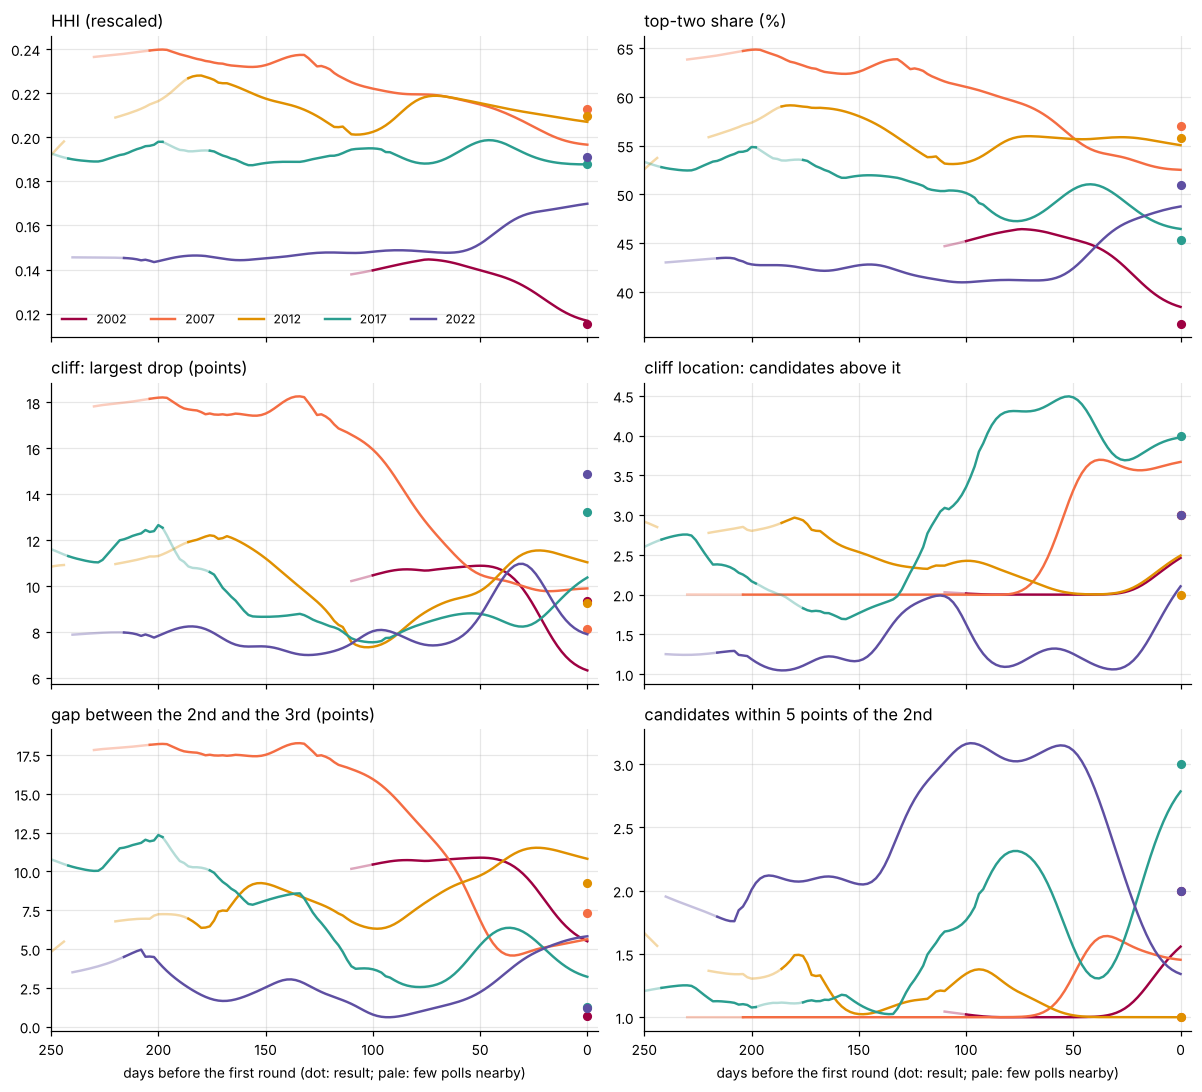

In [4]:
GRID = np.arange(0, 366, 2)
show = {"hhi": "HHI (rescaled)", "top2_share": "top-two share (%)",
        "cliff": "cliff: largest drop (points)", "cliff_location": "cliff location: candidates above it",
        "gap_23": "gap between the 2nd and the 3rd (points)", "n_in_contention": "candidates within 5 points of the 2nd"}
fig, axes = plt.subplots(3, 2, figsize=(11, 10), sharex=True)
evol = []
for ax, (m, label) in zip(axes.flat, show.items()):
    for e in ELECTIONS:
        d = per_poll[per_poll["election"] == e]
        x, y = d["days_before"].to_numpy(), d[m].to_numpy(dtype=float)
        evol.append(average.smooth(x, y, GRID).assign(metric=m, election=e).reset_index())   # strict, for the table
        s = average.smooth(x, y, GRID, adaptive_k=4)                                          # widened, for drawing
        figures.line(ax, s.index, s["mean"], s["sparse"], color=E_COLOURS[e], lw=1.6, label=str(e))
        ax.plot(0, per_result.loc[e, m], "o", color=E_COLOURS[e], ms=5)
    ax.set_title(label, loc="left")
axes[0, 0].legend(frameon=False, ncol=5, fontsize=8)
for ax in axes[-1]:
    ax.set_xlim(250, -5); ax.set_xlabel("days before the first round (dot: result; pale: few polls nearby)")
fig.tight_layout()
fig.savefig(FIGURES / "structure_over_campaign.png")
pd.concat(evol).query("days_before % 14 == 0").round(4).to_csv(TABLES / "structure_poll_average.csv", index=False)